# Exercise 1: Compare NumPy and CuPy transfer paths

## Question

For this PyMUST raw-RF workload and the same CUDA beamformer, does the CuPy path reduce latency compared with passing NumPy arrays from the CPU?

## Hypothesis

Both modes use the CUDA beamformer in mach. CuPy is expected to reduce prepared per-ensemble latency because it keeps geometry on the GPU, uploads each IQ ensemble, and performs Power Doppler reduction there. NumPy passes host arrays to mach; the wrapper stages them for CUDA and returns beamformed output to the CPU for reduction. The output maps should agree within floating-point tolerance.

This is an end-to-end data-placement comparison, not a comparison of the CUDA kernels or an isolated transfer benchmark.

## Pipeline stages and timing scope

| Stage | NumPy host arrays | CuPy GPU-resident | Where its time appears |
|---|---|---|---|
| Dataset load | Load the raw-RF phantom and prepare the workload | Same | Excluded from timing results |
| RF → IQ | CPU conversion | CPU conversion | Timed separately with one warmup and 10 repeats; one shared CPU-only p50 is reported for context and is not included in either cold or warm path timing |
| Static geometry setup | No GPU copy during setup; geometry remains in host arrays; mach stages geometry for CUDA on each call | Receiver positions, scan-grid positions, and transmit arrival times are copied to the GPU once per process/configuration | CuPy geometry copy is in the cold timer and excluded from warm calls; NumPy geometry staging remains in each mach call |
| Per-ensemble IQ handling | Host IQ is passed to mach and staged internally | The 32-frame IQ block is uploaded once per call; geometry stays resident | Included in the cold first call and every warm pipeline call. Only CuPy upload has a separate timer |
| CUDA beamforming | Same CUDA beamformer in mach; its NumPy result returns to the host | Same CUDA beamformer; result remains on the GPU | Included in both cold and warm pipeline timers |
| Power Doppler reduction and host output | Power is reduced on the CPU after beamformed output returns | Power is reduced on the GPU; the scalar feature and final map return to the CPU | Included in both timers; reduction is not timed separately |

_Geometry_ means receiver positions, scan-grid positions, and transmit arrival times. NumPy passes these host arrays to mach; its [Python wrapper](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/kernel.py#L208-L285) and [CUDA binding](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/kernel.cu#L1073-L1215) document the staging and output path.

_Power Doppler_ reduction means turning the 32 beamformed complex IQ frames into one power value per grid point: take the squared magnitude of each frame and sum across the frame axis. NumPy performs this sum on the CPU after mach returns beamformed data; CuPy performs it on the GPU and copies the reduced map to the host.

**Warm pipeline** is the wall time for one prepared ensemble (batch size of 32 frames): IQ handling (including NumPy IQ/geometry staging), CUDA beamforming, Power Doppler reduction, and making the result available on the host. It excludes dataset loading, RF-to-IQ, and one-time geometry setup.

**Cold setup + first ensemble** is measured from just before geometry preparation until the first Power Doppler map is ready on the host. It includes geometry preparation and one complete ensemble path using the already converted IQ block. NumPy's first CUDA use occurs inside the first mach call; CuPy's occurs during geometry upload/setup. It excludes RF-to-IQ.

The shared RF-to-IQ p50 is a separate CPU reference for the same workload. It shows the scale of preprocessing relative to the GPU-path measurements and is not summed with either pipeline timing.

The benchmark repeats one preconverted 32-frame IQ block to measure latency variation; it does not replay 200 distinct acquisitions. A live stream would convert each new RF ensemble to IQ on the CPU and upload that new IQ block.

Both pipeline timers combine transfers, beamforming, Power Doppler reduction, and output handling. They do not isolate beamformer-kernel time from reduction time, so this comparison cannot attribute CuPy's end-to-end improvement to either stage alone. A profiler or separate stage timers would be needed for that attribution.

The input is a rotating-disk tissue-mimicking phantom, not a brain fUSI recording. These measurements do not include a live acquisition queue or capture-to-display latency.

## Procedure

Run both modes on the same Colab T4, dataset, grid, and batch size. Check input fingerprints and output maps before comparing times. Report the warmed latency distribution, the shared CPU RF-to-IQ p50, and one cold first-result observation per mode. Use Nsight Systems on a fixed Linux NVIDIA instance to inspect transfer and synchronization costs.

This run uses a 251 × 251 grid, batch size 32, 10 warmups, and 200 measured calls per mode. The short smoke check is separate.


## Prepare the Colab runtime

Connect this notebook to the Colab T4 kernel in VS Code. In the Colab terminal, update the project checkout from GitHub:

```bash
cd /content/realtime-beamforming-lab && git pull --ff-only origin main
```

The terminal and notebook kernel share the T4 runtime. The next cell checks that the checkout is present.


In [ ]:
from pathlib import Path
import os

repo = Path("/content/realtime-beamforming-lab")
assert (repo / "pyproject.toml").is_file(), (
    f"Clone the GitHub repository into Colab at {repo}"
)
assert (repo / "src/beamforming_lab/benchmark.py").is_file(), "The GitHub checkout is incomplete"
os.chdir(repo)
print(f"Using checkout: {repo}")


In [ ]:
!nvidia-smi


## Install the Colab GPU dependencies

Run this once in a fresh runtime. It removes conflicting CuPy wheels and installs the project with its Colab GPU dependencies. Restart the notebook kernel after installation, then run the checks below before benchmarking.


In [ ]:
%pip uninstall -y cupy-cuda12x cupy-cuda13x
%pip install --no-cache-dir -e '.[gpu-colab]'


In [1]:
from pathlib import Path
import importlib.metadata as metadata
import os
import cupy as cp

repo = Path("/content/realtime-beamforming-lab")
assert (repo / "pyproject.toml").is_file(), "The GitHub checkout is missing after kernel restart"
os.chdir(repo)
cupy_wheels = sorted(
    dist.metadata.get("Name", "")
    for dist in metadata.distributions()
    if dist.metadata.get("Name", "").lower().startswith("cupy-cuda")
)
print("CuPy module:", cp.__file__)
print("CuPy wheels:", cupy_wheels)
print("CUDA devices:", cp.cuda.runtime.getDeviceCount())
print("CUDA runtime:", cp.cuda.runtime.runtimeGetVersion())
assert cp.cuda.runtime.getDeviceCount() > 0
assert len(cupy_wheels) == 1 and cupy_wheels[0].lower() == "cupy-cuda13x", cupy_wheels
cp.cuda.Device().synchronize()


CuPy module: /usr/local/lib/python3.13/dist-packages/cupy/__init__.py
CuPy wheels: ['cupy-cuda13x']
CUDA devices: 1
CUDA runtime: 13000


## Set the comparison conditions

Each mode runs in a fresh process with the same preconverted IQ block, 251 × 251 grid, and 32-frame batch. It makes one cold first-result call, 10 warmups, and 200 timed calls. Repeating a fixed block controls the workload; CuPy uploads IQ on every call while reusing its prepared geometry.

The timer boundaries and included stages are defined above. The shared CPU RF-to-IQ p50 is measured before either GPU-path process. The diagram below summarizes the per-mode paths; stage widths are conceptual, not measured durations.

Reports are saved in results/. Power Doppler maps are saved in artifacts/ for the output comparison.


In [2]:
from pathlib import Path

RUNS = 200
WARMUP = 10
BATCH_SIZE = 32
GRID_SIZE = 251

results_dir = repo / "results"
artifacts_dir = repo / "artifacts"
results_dir.mkdir(exist_ok=True)
artifacts_dir.mkdir(exist_ok=True)

report_paths = {
    "numpy": results_dir / "exercise1-pymust-numpy.json",
    "cupy": results_dir / "exercise1-pymust-cupy.json",
}
power_paths = {
    "numpy": artifacts_dir / "exercise1-pymust-numpy-power.npy",
    "cupy": artifacts_dir / "exercise1-pymust-cupy-power.npy",
}
print(f"Conditions: {RUNS} measured runs, {WARMUP} warmups, batch size {BATCH_SIZE}, grid {GRID_SIZE} × {GRID_SIZE}")


Conditions: 200 measured runs, 10 warmups, batch size 32, grid 251 × 251


## Measure the shared CPU RF-to-IQ reference

This times the same conversion used to prepare the benchmark IQ block, on the same raw-RF input. It runs once before either GPU-path process: one untimed warmup followed by 10 timed conversions. The p50 is shared context for both modes; it is not included in the warm pipeline or cold setup + first ensemble measurements.


In [3]:
import hashlib
import json
import time
import numpy as np
from mach.io.must import download_pymust_doppler_data, extract_pymust_params
from beamforming_lab.workload import convert_rf_to_iq

mat_data = download_pymust_doppler_data()
params = extract_pymust_params(mat_data)
raw_rf = np.asarray(mat_data["RF"])
canonical_rf = np.ascontiguousarray(raw_rf)
fingerprint = hashlib.sha256()
fingerprint.update(canonical_rf.dtype.str.encode("ascii"))
fingerprint.update(np.asarray(canonical_rf.shape, dtype="<i8").tobytes())
fingerprint.update(canonical_rf.tobytes(order="C"))
rf_array_sha256 = fingerprint.hexdigest()
rf_data = raw_rf.astype(float)
RF_IQ_WARMUPS = 1
RF_IQ_RUNS = 10
for _ in range(RF_IQ_WARMUPS):
    convert_rf_to_iq(rf_data, params)

rf_to_iq_samples_ms = []
for _ in range(RF_IQ_RUNS):
    started_ns = time.perf_counter_ns()
    convert_rf_to_iq(rf_data, params)
    rf_to_iq_samples_ms.append((time.perf_counter_ns() - started_ns) / 1_000_000)

shared_rf_to_iq_p50_ms = float(np.percentile(rf_to_iq_samples_ms, 50))
timing_summary = {
    "dataset": "PyMUST rotating-disk Doppler raw-RF phantom",
    "rf_array_sha256": rf_array_sha256,
    "warmup_runs": RF_IQ_WARMUPS,
    "timed_runs": RF_IQ_RUNS,
    "samples_ms": rf_to_iq_samples_ms,
    "p50_ms": shared_rf_to_iq_p50_ms,
    "scope": (
        "CPU pymust.rf2iq plus transpose and contiguous complex64 layout conversion; "
        "separate shared reference, not included in either GPU-path timer."
    ),
}
rf_to_iq_timing_path = results_dir / "exercise1-pymust-rf-to-iq.json"
rf_to_iq_timing_path.write_text(json.dumps(timing_summary, indent=2) + "\n")

print(
    f"Shared CPU RF-to-IQ p50={shared_rf_to_iq_p50_ms:.2f} ms "
    f"({RF_IQ_RUNS} timed conversions after {RF_IQ_WARMUPS} warmup)"
)
print(f"Saved shared timing: {rf_to_iq_timing_path}")


Shared CPU RF-to-IQ p50=275.89 ms (10 timed conversions after 1 warmup)
Saved shared timing: /content/realtime-beamforming-lab/results/exercise1-pymust-rf-to-iq.json


### Timing diagram

![Cold and warm timing scopes for the NumPy and CuPy paths](../results/exercise1-timing-scope.svg)


## Run the matched benchmarks

Each command starts a fresh beamform-lab process from the same dataset. In each process, one cold call records geometry setup through the first Power Doppler map; it is followed by 10 warmups and 200 measured ensemble calls. Warmup times are discarded.

The per-ensemble wall timer covers IQ handling/staging, the CUDA beamformer, Power Doppler reduction, and host output. NumPy stages host IQ and geometry inside mach and reduces on the CPU. CuPy uploads IQ each call, reuses GPU geometry, reduces on the GPU, and copies the final map to the host. The shared CPU RF-to-IQ p50 is measured separately and is not added to either pipeline time. The separate upload metric isolates only CuPy IQ upload; NumPy transfers are not isolated.

Across both fresh processes, there are 2 cold calls, 20 warmups, and 400 measured calls (422 ensemble calls total).


In [4]:
import json
import subprocess

for mode in ("numpy", "cupy"):
    command = [
        "beamform-lab", "benchmark",
        "--dataset", "pymust",
        "--mode", mode,
        "--measure-cold-start",
        "--runs", str(RUNS),
        "--warmup", str(WARMUP),
        "--batch-size", str(BATCH_SIZE),
        "--grid-size", str(GRID_SIZE),
        "--output", str(report_paths[mode]),
        "--save-power", str(power_paths[mode]),
    ]
    print("\nRunning:", " ".join(command), flush=True)
    completed = subprocess.run(command, cwd=repo, text=True, capture_output=True)
    if completed.returncode:
        print(completed.stdout[-4000:])
        print(completed.stderr[-4000:])
        completed.check_returncode()
    report = json.loads(report_paths[mode].read_text())
    pipeline = report["ensemble_pipeline_wall_ms"]
    cold = report["cold_start_measurement"]
    print(
        f"{mode}: GPU={report['runtime_provenance']['gpu']['name']}; "
        f"pipeline p50={pipeline['p50']:.2f} ms, p95={pipeline['p95']:.2f} ms; "
        f"cold setup + first ensemble="
        f"{cold['device_setup_plus_first_ensemble_wall_ms']:.2f} ms; "
        f"report={report_paths[mode].name}"
    )



Running: beamform-lab benchmark --dataset pymust --mode numpy --measure-cold-start --runs 200 --warmup 10 --batch-size 32 --grid-size 251 --output /content/realtime-beamforming-lab/results/exercise1-pymust-numpy.json --save-power /content/realtime-beamforming-lab/artifacts/exercise1-pymust-numpy-power.npy
numpy: GPU=Tesla T4; pipeline p50=16.66 ms, p95=18.96 ms; cold setup + first ensemble=202.59 ms; report=exercise1-pymust-numpy.json

Running: beamform-lab benchmark --dataset pymust --mode cupy --measure-cold-start --runs 200 --warmup 10 --batch-size 32 --grid-size 251 --output /content/realtime-beamforming-lab/results/exercise1-pymust-cupy.json --save-power /content/realtime-beamforming-lab/artifacts/exercise1-pymust-cupy-power.npy
cupy: GPU=Tesla T4; pipeline p50=4.99 ms, p95=7.28 ms; cold setup + first ensemble=1019.81 ms; report=exercise1-pymust-cupy.json


## Check the pair, then compare outputs

Confirm both reports used the same RF fingerprint as the shared RF-to-IQ timing, grid, batch size, run counts, and GPU. Then compare the Power Doppler maps. Small floating-point differences are expected; the check does not require bitwise equality.


In [5]:
import json
import numpy as np

reports = {mode: json.loads(report_paths[mode].read_text()) for mode in ("numpy", "cupy")}
power_maps = {mode: np.load(power_paths[mode]) for mode in ("numpy", "cupy")}

numpy_report, cupy_report = reports["numpy"], reports["cupy"]
assert numpy_report["data_provenance"]["rf_array_sha256"] == cupy_report["data_provenance"]["rf_array_sha256"]
assert numpy_report["data_provenance"]["rf_array_sha256"] == rf_array_sha256
assert numpy_report["scan_grid_points"] == cupy_report["scan_grid_points"]
assert numpy_report["batch_size_frames"] == cupy_report["batch_size_frames"] == BATCH_SIZE
assert numpy_report["measurement_runs"] == cupy_report["measurement_runs"] == RUNS
assert numpy_report["warmup_runs"] == cupy_report["warmup_runs"] == WARMUP
assert numpy_report["runtime_provenance"]["gpu"]["name"] == cupy_report["runtime_provenance"]["gpu"]["name"]
assert power_maps["numpy"].shape == power_maps["cupy"].shape

numpy_map = power_maps["numpy"].astype(np.float64)
cupy_map = power_maps["cupy"].astype(np.float64)
difference = cupy_map - numpy_map
scale = max(float(np.linalg.norm(numpy_map.ravel())), np.finfo(np.float64).tiny)
relative_l2_error = float(np.linalg.norm(difference.ravel()) / scale)
shared_peak = max(float(np.max(numpy_map)), float(np.max(cupy_map)), np.finfo(np.float64).tiny)
max_abs_error = float(np.max(np.abs(difference)))
peak_relative_error = max_abs_error / shared_peak
correlation = float(np.corrcoef(numpy_map.ravel(), cupy_map.ravel())[0, 1])

print(f"Output shape: {numpy_map.shape}")
print(f"Mean Power Doppler feature — NumPy: {numpy_report['mean_output_feature']:.6g}; CuPy: {cupy_report['mean_output_feature']:.6g}")
print(f"Normalized L2 map error: {relative_l2_error:.3e}")
print(f"Maximum absolute map error: {max_abs_error:.6g} ({peak_relative_error:.3e} of shared peak)")
print(f"Pixel-wise map correlation: {correlation:.8f}")

print(f"Shared CPU RF-to-IQ p50: {shared_rf_to_iq_p50_ms:.2f} ms; excluded from both GPU-path timers.")


Output shape: (251, 251)
Mean Power Doppler feature — NumPy: 7.12192e+08; CuPy: 7.12192e+08
Normalized L2 map error: 5.874e-08
Maximum absolute map error: 1024 (1.405e-07 of shared peak)
Pixel-wise map correlation: 1.00000000
Shared CPU RF-to-IQ p50: 275.89 ms; excluded from both GPU-path timers.


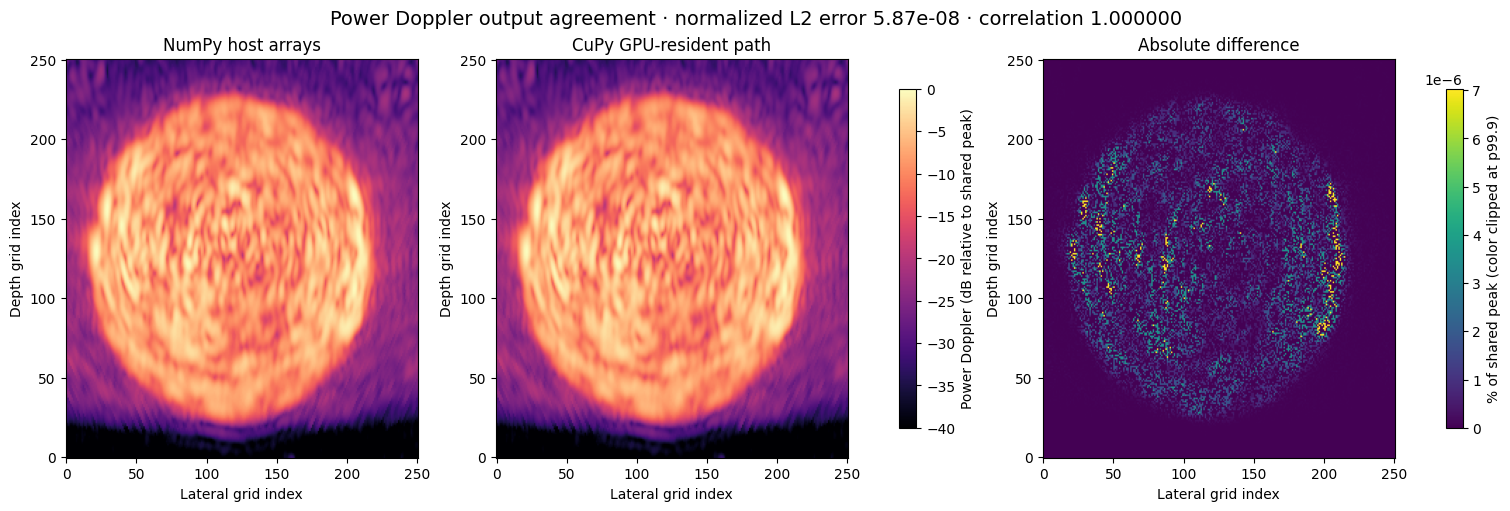

Saved /content/realtime-beamforming-lab/results/exercise1-pymust-output-comparison.png


In [6]:
import matplotlib.pyplot as plt

shared_peak = max(float(np.max(numpy_map)), float(np.max(cupy_map)), np.finfo(np.float64).tiny)
floor = 1e-4
numpy_db = 10 * np.log10(np.maximum(numpy_map / shared_peak, floor))
cupy_db = 10 * np.log10(np.maximum(cupy_map / shared_peak, floor))
abs_difference_percent = 100 * np.abs(difference) / shared_peak
diff_vmax = max(float(np.percentile(abs_difference_percent, 99.9)), 1e-6)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for ax, image, title in [
    (axes[0], numpy_db, "NumPy host arrays"),
    (axes[1], cupy_db, "CuPy GPU-resident path"),
]:
    view = ax.imshow(image.T, origin="lower", cmap="magma", vmin=-40, vmax=0, aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("Lateral grid index")
    ax.set_ylabel("Depth grid index")
fig.colorbar(view, ax=axes[:2], label="Power Doppler (dB relative to shared peak)", shrink=0.85)

error_view = axes[2].imshow(
    abs_difference_percent.T, origin="lower", cmap="viridis", vmin=0, vmax=diff_vmax, aspect="auto"
)
axes[2].set_title("Absolute difference")
axes[2].set_xlabel("Lateral grid index")
axes[2].set_ylabel("Depth grid index")
fig.colorbar(error_view, ax=axes[2], label="% of shared peak (color clipped at p99.9)", shrink=0.85)
fig.suptitle(
    f"Power Doppler output agreement · normalized L2 error {relative_l2_error:.2e} · correlation {correlation:.6f}",
    fontsize=14,
)
output_plot_path = results_dir / "exercise1-pymust-output-comparison.png"
fig.savefig(output_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {output_plot_path}")


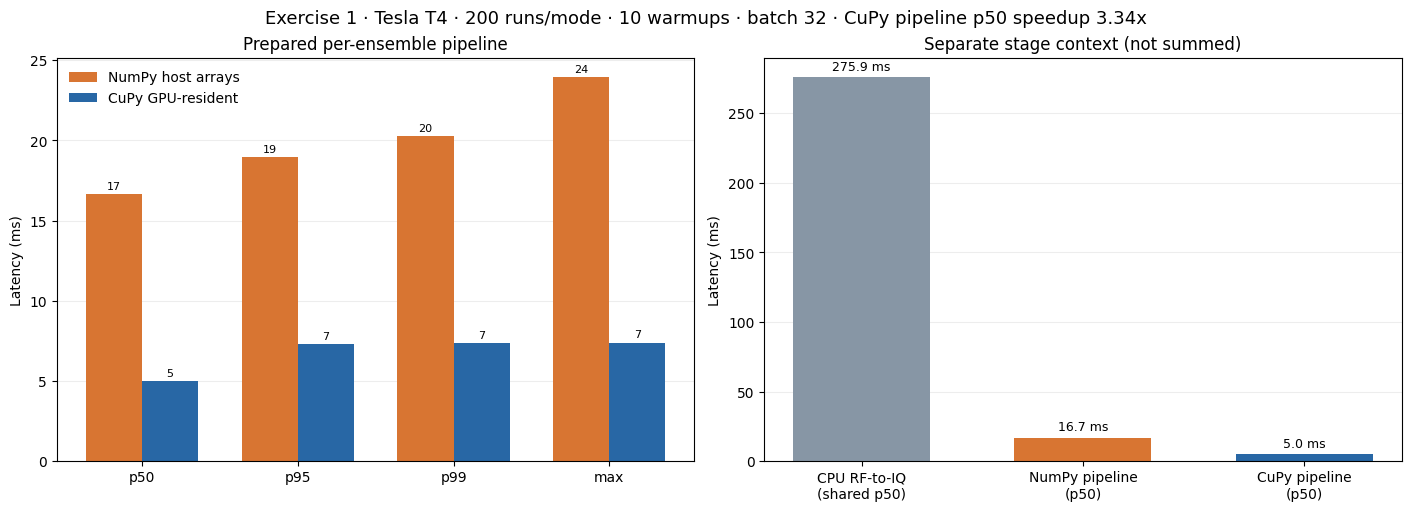

Saved /content/realtime-beamforming-lab/results/exercise1-pymust-latency-comparison.png
Pipeline p50: NumPy 16.66 ms; CuPy 4.99 ms; ratio 3.34x
Shared CPU RF-to-IQ p50: 275.89 ms across 10 timed conversions


In [7]:
import matplotlib.pyplot as plt
import numpy as np

percentiles = ("p50", "p95", "p99", "max")
mode_labels = {"numpy": "NumPy host arrays", "cupy": "CuPy GPU-resident"}
colors = {"numpy": "#D87532", "cupy": "#2867A5"}
metric = "ensemble_pipeline_wall_ms"

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
x = np.arange(len(percentiles))
width = 0.36
for offset, mode in ((-width / 2, "numpy"), (width / 2, "cupy")):
    values = [reports[mode][metric][key] for key in percentiles]
    bars = axes[0].bar(x + offset, values, width, label=mode_labels[mode], color=colors[mode])
    axes[0].bar_label(bars, fmt="%.0f", padding=2, fontsize=8)
axes[0].set_title("Prepared per-ensemble pipeline")
axes[0].set_xticks(x, percentiles)
axes[0].set_ylabel("Latency (ms)")
axes[0].grid(axis="y", alpha=0.22)
axes[0].set_axisbelow(True)
axes[0].legend(frameon=False)

stage_labels = ["CPU RF-to-IQ\n(shared p50)", "NumPy pipeline\n(p50)", "CuPy pipeline\n(p50)"]
stage_values = [
    shared_rf_to_iq_p50_ms,
    reports["numpy"][metric]["p50"],
    reports["cupy"][metric]["p50"],
]
stage_colors = ["#8796A5", colors["numpy"], colors["cupy"]]
bars = axes[1].bar(stage_labels, stage_values, color=stage_colors, width=0.62)
axes[1].bar_label(bars, fmt="%.1f ms", padding=3, fontsize=9)
axes[1].set_title("Separate stage context (not summed)")
axes[1].set_ylabel("Latency (ms)")
axes[1].grid(axis="y", alpha=0.22)
axes[1].set_axisbelow(True)

numpy_p50 = reports["numpy"][metric]["p50"]
cupy_p50 = reports["cupy"][metric]["p50"]
cupy_speedup = numpy_p50 / cupy_p50 if cupy_p50 else float("nan")
gpu_name = reports["cupy"]["runtime_provenance"]["gpu"]["name"]
fig.suptitle(
    f"Exercise 1 · {gpu_name} · {RUNS} runs/mode · {WARMUP} warmups · "
    f"batch {BATCH_SIZE} · CuPy pipeline p50 speedup {cupy_speedup:.2f}x",
    fontsize=13,
)
timing_plot_path = results_dir / "exercise1-pymust-latency-comparison.png"
fig.savefig(timing_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {timing_plot_path}")
print(
    f"Pipeline p50: NumPy {numpy_p50:.2f} ms; CuPy {cupy_p50:.2f} ms; "
    f"ratio {cupy_speedup:.2f}x"
)
print(
    f"Shared CPU RF-to-IQ p50: {shared_rf_to_iq_p50_ms:.2f} ms "
    f"across {RF_IQ_RUNS} timed conversions"
)


### Cold setup + first ensemble

device_setup_plus_first_ensemble_wall_ms is a direct cold wall timer: it starts immediately before geometry preparation and ends after the first Power Doppler map is ready on the host. It includes one complete ensemble path using preconverted IQ. NumPy's first CUDA use is inside its first mach call; CuPy initializes CUDA during geometry upload/setup. Dataset loading and RF-to-IQ conversion happen before this timer.

This is one cold observation per mode. No acquisition or RF-to-IQ time is added to it.


## Results from this T4 run

The runs used the same Tesla T4, RF fingerprint, 251 × 251 grid, and batch size 32. Each mode had 10 warmups and 200 measured calls. Their Power Doppler maps agree closely: normalized L2 error 5.87 × 10⁻⁸, correlation 1.00000000, and maximum difference 1.41 × 10⁻⁷ of the shared peak.

| Measurement | NumPy | CuPy |
|---|---:|---:|
| Warm pipeline p50 / p95 | 16.66 / 18.96 ms | 4.99 / 7.28 ms |
| Cold setup + first ensemble | 202.59 ms | 1019.81 ms |
| Shared CPU RF-to-IQ p50, separate reference | 275.89 ms | 275.89 ms |

For this run, the prepared CuPy pipeline was 3.34× faster at p50 and 2.60× faster at p95. The shared CPU RF-to-IQ p50 is substantially longer than either prepared-pipeline p50, so preprocessing is important context for the end-to-end pipeline. It is measured separately and is not added to the GPU-path timings or presented as live capture-to-display latency.

Cold setup + first ensemble is one observation per mode. It includes geometry preparation and one complete ensemble through Power Doppler reduction and host output, using the already converted IQ block. CuPy's first call was slower in this run because its GPU setup and first ensemble are both included. The shared RF-to-IQ measurement is excluded from this cold timer too.

**Practical takeaway.** CuPy is most likely to pay off when many 32-frame ensembles are processed while the probe and scan geometry stay fixed and the prepared process is reused. In this run, CuPy’s cold setup + first ensemble was about 817 ms longer, while its warm p50 was about 11.67 ms shorter per ensemble. Those values suggest a rough crossover near 71 total ensembles: the initial cold call plus about 70 further ensembles. Treat that as an estimate for this T4 workload, since each mode had only one cold observation and the 200 measured calls replayed one preconverted IQ block.

Both modes call the same CUDA beamformer in mach. The prepared-pipeline wall time also includes host/device staging, Power Doppler reduction, and output handling; NumPy reduces on the CPU and CuPy on the GPU. These end-to-end measurements show that the complete CuPy path was faster in this run, but they do not identify whether the gain comes from beamforming, reduction, or data movement. The benchmark repeats one IQ block and does not measure a stream of distinct ensembles. The phantom is a pipeline workload, not a brain fUSI recording.